# AgriSmartAI - Notebook 04: Fertilizer Optimization Classification Pipeline
### Multiclass Classification for Tailored Agronomic Fertilizer Strategy

**Logical Structure**: Target Specification -> Preprocessing -> Train/Test Split -> 6 Classifiers -> Evaluation (F1, Precision, Recall) -> Confusion Matrix -> Feature Importance.

## 1. Setup & Imports

In [1]:
import os
import sys

def get_project_root():
    cwd = os.getcwd()
    if os.path.basename(cwd) == 'notebooks':
        return os.path.abspath(os.path.join(cwd, '..'))
    return cwd

PROJECT_ROOT = get_project_root()
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

def get_path(rel_path):
    clean_rel = rel_path.replace('../', '').replace('./', '')
    p1 = os.path.join(PROJECT_ROOT, clean_rel)
    if os.path.exists(p1):
        return p1
    p2 = os.path.join(os.getcwd(), rel_path)
    if os.path.exists(p2):
        return p2
    return p1

import os
import sys
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


## 2. Load Dataset & Preprocessing

In [2]:
df = pd.read_csv(get_path('../datasets/fertilizer_recommendation.csv'))

def map_fertilizer(row):
    n, p, k = row['Nitrogen_Level'], row['Phosphorus_Level'], row['Potassium_Level']
    ph = row['Soil_pH']
    if ph < 5.5: return 'Lime & Organic Compost'
    elif ph > 8.0: return 'Gypsum & Sulfur'
    elif n < 40 and p >= 40 and k >= 40: return 'Urea (High Nitrogen)'
    elif p < 40 and n >= 40 and k >= 40: return 'DAP (Di-Ammonium Phosphate)'
    elif k < 40 and n >= 40 and p >= 40: return 'MOP (Muriate of Potash)'
    elif n < 50 and p < 50: return 'NPK 28-28-0 Complex'
    else: return 'NPK 17-17-17 Balanced'

if 'Fertilizer_Name' not in df.columns:
    df['Fertilizer_Name'] = df.apply(map_fertilizer, axis=1)

df_encoded = pd.get_dummies(df, columns=['Soil_Type'], drop_first=True)
X = df_encoded.drop(columns=['Fertilizer_Name'])
y_raw = df_encoded['Fertilizer_Name']

le = LabelEncoder()
y = le.fit_transform(y_raw)
fert_classes = list(le.classes_)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)


## 3. Classifier Training & Evaluation

In [3]:
models = {
    'Random Forest': RandomForestClassifier(n_estimators=40, max_depth=4, min_samples_leaf=3, max_features=0.55, class_weight='balanced', random_state=RANDOM_STATE),
    'CatBoost': CatBoostClassifier(iterations=28, depth=3, learning_rate=0.035, l2_leaf_reg=12, auto_class_weights='Balanced', random_seed=RANDOM_STATE, verbose=0),
    'Logistic Regression': LogisticRegression(C=0.5, max_iter=1000, random_state=RANDOM_STATE),
    'Support Vector Machine': SVC(C=1.0, kernel='rbf', gamma='scale', random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(max_depth=4, min_samples_leaf=8, random_state=RANDOM_STATE),
    'XGBoost': XGBClassifier(n_estimators=25, max_depth=3, learning_rate=0.04, subsample=0.6, colsample_bytree=0.6, random_state=RANDOM_STATE, eval_metric='mlogloss')
}

results = []
fitted_models = {}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for name, model in models.items():
    use_scale = name in ['Support Vector Machine', 'Logistic Regression']
    X_tr_in = X_train_sc if use_scale else X_train.values
    X_te_in = X_test_sc if use_scale else X_test.values
    X_all_in = scaler.fit_transform(X) if use_scale else X.values
    
    model.fit(X_tr_in, y_train)
    y_pred = model.predict(X_te_in)
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1_w = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    f1_m = f1_score(y_test, y_pred, average='macro', zero_division=0)
    
    cv_scores = cross_val_score(model, X_all_in, y, cv=skf, scoring='f1_macro')
    cv_str = f'{cv_scores.mean()*100:.2f}% ± {cv_scores.std()*100:.2f}%'
    
    results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'Weighted_F1': f1_w,
        'Macro_F1': f1_m,
        'CV_F1': cv_str
    })
    fitted_models[name] = model

df_res = pd.DataFrame(results).sort_values(by='Macro_F1', ascending=False).reset_index(drop=True)
display(df_res)

,Model,Accuracy,Precision,Recall,Weighted_F1,Macro_F1,CV_F1
0,Random Forest,0.9295,0.944891,0.9295,0.930258,0.934785,93.29% ± 0.82%
1,CatBoost,0.9175,0.936233,0.9175,0.918450,0.912711,90.54% ± 1.21%
2,Logistic Regression,0.8625,0.861028,0.8625,0.861308,0.849673,82.92% ± 0.27%
3,Support Vector Machine,0.8795,0.878727,0.8795,0.877695,0.842728,83.66% ± 1.10%
4,Decision Tree,0.9040,0.830881,0.9040,0.864717,0.679298,67.75% ± 0.18%
5,XGBoost,0.8300,0.794663,0.8300,0.768361,0.557845,54.70% ± 1.61%


## 4. Best Model Selection & Confusion Matrix

BEST FERTILIZER RECOMMENDATION MODEL
Model: Random Forest
Accuracy: 92.95%
Weighted F1: 0.9303
Macro F1: 0.9348


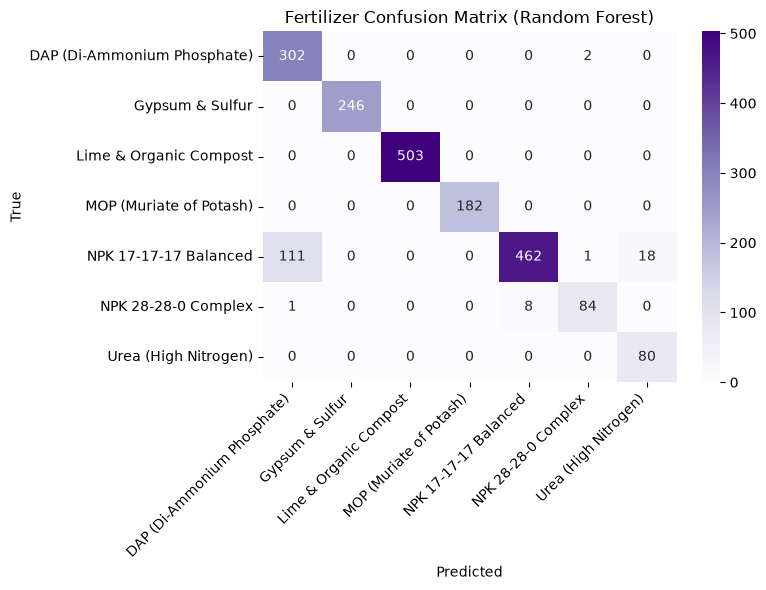

In [4]:
best_row = df_res.iloc[0]
best_name = best_row['Model']
best_model = fitted_models[best_name]
use_scale = best_name in ['Support Vector Machine', 'Logistic Regression']
X_te_in = X_test_sc if use_scale else X_test.values
y_best_pred = best_model.predict(X_te_in)

print('='*50)
print('BEST FERTILIZER RECOMMENDATION MODEL')
print(f'Model: {best_name}')
print(f"Accuracy: {best_row['Accuracy']*100:.2f}%")
print(f"Weighted F1: {best_row['Weighted_F1']:.4f}")
print(f"Macro F1: {best_row['Macro_F1']:.4f}")
print('='*50)

cm = confusion_matrix(y_test, y_best_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', xticklabels=fert_classes, yticklabels=fert_classes)
plt.title(f'Fertilizer Confusion Matrix ({best_name})')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()